## Following kernels will load source name text files into a filtered ARCHS4 database

### Function to load sample names from text file

In [1]:
import glob
import sys
import h5py
import archs4py as a4
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
def load_sample_names(txt_file_path):
    """Load sample names from a text file"""
    with open(txt_file_path, 'r') as f:
        sample_names = [line.strip() for line in f if line.strip()]
    return sample_names

In [4]:
%cd /scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/
class_sample_dict = dict()

# loop through all file paths in current directory to find files of interest
for filename in glob.glob("*3.txt"):
    file_path = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/" + filename
    # sample_names are within the text files and are the values of the class_sample_dict
    sample_names = load_sample_names(file_path)
    # class names are within the names of the text files
    class_name = filename.replace("3.txt","")

    class_sample_dict[class_name] = sample_names

/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class


In [5]:
class_sample_dict

{'Macrophage': ['PCA-ASSOCIATED CD14+CD11B+ MACROPHAGES',
  'WT ESC-DERIVED MACROPHAGE',
  'PERIPHERAL BLOOD MONOCYTE-DERIVED MACROPHAGES',
  'PRIMARY MACROPHAGE',
  'PRIMARY HUMAN MONOCYTE-DERIVED MACROPHAGES, ADMAF, IFN-Î³',
  'MACROPHAGE WITH CONTROL LNA 24H_REP#2',
  'MACROPHAGE_6D_MEDIA_MTB_4H',
  'PRIMARY HUMAN MACROPHAGE CELLS',
  'H1 ESC-DERIVED M1 MACROPHAGES',
  'MACROPHAGES(BC9)',
  'HUMAN MONOCYTE-DERIVED MACROPHAGE',
  'ACTIVATED MONOCYTE-DERIVED MACROPHAGES',
  'PERIPHERAL_BLOOD_MACROPHAGE-M0_SICTRL',
  'IPSC-DERIVED M0 MACROPHAGE',
  'HU-CB-MACROPHAGE-RNA, WT-CB',
  'BONE MARROW DERIVED MACROPHAGE',
  'HUMAN HEALTHY BLOOD DONOR MONOCYTES-DERIVED MACROPHAGES',
  'MACROPHAGES',
  'MONOCYTE-DERIVED MACROPHAGES, SSC',
  'PERIPHERAL BLOOD MONOCYTE-DERIVED MACROPHAGES NATURAL',
  'MACROPHAGE IN NORMOXIA 48H',
  'RNA FROM MONOCYTE-DERIVED MACROPHAGES 4 HOURS AFTER CULTURED WITHOUT VIRUS',
  'HUMAN IPSCS-DERIVED MACROPHAGES',
  'PRIMARY HUMAN MONOCYTE-DERIVED MACROPHAGES',
  'HU

### Filters human_tpm_v2.2_NOSC.h5 into a filtered file containing source names in class_sample_dict

In [6]:
transcript_file_path = "/scratch/by2372/pipeline/ARCHS4_Macrophages/human_tpm_v2.2_NOSC.h5"
a4.ls(transcript_file_path)

data                      
│ expression            float32 | (271742, 661840)
meta                      
│ samples                   
│   characteristics_ch1   str    | (661840,)
│   source_name_ch1       str    | (661840,)
│ transcripts               
│   ensembl_id            str    | (271742,)
│   symbol                str    | (271742,)


In [7]:

with h5py.File(transcript_file_path, "r") as fin, h5py.File('filtered_ARCHS4_4_class.h5', 'w') as fout:

    # copy the ensembl_ids and gene symbols to the new h5 file
    fin.copy("meta/transcripts/ensembl_id", fout)
    fin.copy("meta/transcripts/symbol", fout) 
    
    # Navigate to the metadata group for source names
    source_name_ds = fin['meta/samples/source_name_ch1']

    # Read all names and decode bytes to strings
    source_names = source_name_ds[:]
    if isinstance(source_names[0], bytes):
        source_names = [s.decode('utf-8') for s in source_names]

    # Get dataset info
    expr_dataset = fin['data/expression']
    n_genes, n_samples = expr_dataset.shape

    filtered_dataset = fout.create_dataset(
        "data/filtered_expression",
        (n_genes, 0),                    # start with 0 samples
        maxshape=(n_genes, None),        # allow dynamic extension
        dtype=expr_dataset.dtype,
        chunks=True
    )
    
    class_name_dataset = fout.create_dataset(
        "class_name",
        (0,),                            # start empty
        maxshape=(None,),                # allow appending
        dtype=source_name_ds.dtype,
        chunks=True
    )

    current_pos = 0

    for key, value in class_sample_dict.items():

        print("Matching indices for " + str(key))

        
        matched_indices = []
        class_names = []
        
        for filt_name in set(value): 
            matched_indices.extend([
                i for i, n in enumerate(source_names)
                if n.lower() == filt_name.lower()
            ])

        matched_indices.sort()
        n_new = len(matched_indices)
        print(str(n_new))
        cur_class_names = [key] * n_new
        class_names.append(cur_class_names)

        filtered_dataset.resize((n_genes, current_pos + n_new))
        class_name_dataset.resize((current_pos + n_new,))
        
        # Process in chunks of genes instead of loading all at once
        chunk_size = 1000  # Adjust based on your memory
        iteration = 0
        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)
            
            # Read chunk of data for matched samples only
            chunk_data = expr_dataset[start_gene:end_gene, matched_indices]
            
            # Write to output
            filtered_dataset[start_gene:end_gene, current_pos:current_pos + n_new] = chunk_data
            iteration = iteration + 1
            print("Iteration " + str(iteration)+ " is done.")
            sys.stdout.flush()


        class_name_dataset[current_pos:current_pos + n_new] = class_names
        
        current_pos += n_new

Matching indices for Macrophage
4183
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.
Iteration 11 is done.
Iteration 12 is done.
Iteration 13 is done.
Iteration 14 is done.
Iteration 15 is done.
Iteration 16 is done.
Iteration 17 is done.
Iteration 18 is done.
Iteration 19 is done.
Iteration 20 is done.
Iteration 21 is done.
Iteration 22 is done.
Iteration 23 is done.
Iteration 24 is done.
Iteration 25 is done.
Iteration 26 is done.
Iteration 27 is done.
Iteration 28 is done.
Iteration 29 is done.
Iteration 30 is done.
Iteration 31 is done.
Iteration 32 is done.
Iteration 33 is done.
Iteration 34 is done.
Iteration 35 is done.
Iteration 36 is done.
Iteration 37 is done.
Iteration 38 is done.
Iteration 39 is done.
Iteration 40 is done.
Iteration 41 is done.
Iteration 42 is done.
Iteration 43 is done.
Iteration 44 is done.
Iter

# Following code will filter the database for TF genes only

In [8]:
filtered_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_ARCHS4_4_class.h5"
tf_names = load_sample_names("/scratch/by2372/pipeline/tf_names.txt")
a4.ls(filtered_file)

class_name            str    | (10775,)
data                      
│ filtered_expression   float32 | (271742, 10775)
ensembl_id            str    | (271742,)
symbol                str    | (271742,)


In [9]:
# Read in the filtered ARCHS4 h5 and write out to a new h5
with h5py.File(filtered_file, "r") as fin, h5py.File('filtered_ARCHS4_TFs_4_class.h5', 'w') as fout:

    # Copy the class names into the new h5
    fin.copy("class_name", fout) 
    # Read in the gene symbol and ensembl IDs from the input h5 file
    symbols = fin["symbol"]
    ensembl_id = fin["ensembl_id"]

    # unpack the gene symbol names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # unapck the ensembl IDs and decode bytes to strings
    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # initialize the total number of genes in the input h5, an empty matched index list and the processing chunk size
    n_genes = len(symbols)
    tf_matched_indices = []
    chunk_size = 1000

    # iterate through indices of all genes in the input h5 by chunking through them
    for start_gene in range(0, n_genes, chunk_size):
        end_gene = min(start_gene + chunk_size, n_genes)
        chunk_symbols = symbols_unpack[start_gene:end_gene]

        # find the indices that match the list of known human TFs
        for i, sym in enumerate(chunk_symbols):
            if sym in tf_names:
                idx = start_gene + i
                tf_matched_indices.append(idx)

    tf_matched_indices.sort()
    print("Matched indices for TFs have been found")
    
    # Create output dataset for gene symbol in the output h5
    new_sym_dataset = fout.create_dataset(
        "symbol", 
        (len(tf_matched_indices), ),
        dtype=symbols.dtype,
        chunks=True
    )

    # Create output dataset for ensembl ID in the output h5
    new_ensembl_dataset = fout.create_dataset(
        "ensembl_id", 
        (len(tf_matched_indices), ),
        dtype=ensembl_id.dtype,
        chunks=True
    )

    # convert symbols and ensembl IDs to np arrays
    symbols_arr = np.array(symbols_unpack)
    ensembl_arr = np.array(ensembl_unpack)

    # have only the matched indices be the new symbols and ensembl ID datasets
    new_sym_dataset[...] = symbols_arr[tf_matched_indices]
    new_ensembl_dataset[...] = ensembl_arr[tf_matched_indices]

    # Get dataset info
    expr_dataset = fin['data/filtered_expression']
    n_genes, n_samples = expr_dataset.shape

    # Create output dataset
    filtered_dataset = fout.create_dataset(
        "data/filtered_expression", 
        (len(tf_matched_indices), n_samples),
        dtype=expr_dataset.dtype,
        chunks=True
    )

    # do a chunking approach to chunk through the number of samples in 1000 chunks 
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = expr_dataset[tf_matched_indices, start_sample:end_sample]
        filtered_dataset[:, start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1


Matched indices for TFs have been found
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.


In [10]:
filtered_TFs_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_ARCHS4_TFs_4_class.h5"
a4.ls(filtered_TFs_file)

class_name            str    | (10775,)
data                      
│ filtered_expression   float32 | (13146, 10775)
ensembl_id            str    | (13146,)
symbol                str    | (13146,)


# The code below will create training and testing datasets

In [11]:
def chunk_samples(chunk_size, n_samples, n_genes, output, input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)

        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)

            # Read a chunk of the input matrix
            data_chunk = input[start_sample:end_sample, start_gene:end_gene]

            # Write the chunk to the output dataset
            output[start_sample:end_sample, start_gene:end_gene] = data_chunk

        print("Iteration " + str(iteration) + " (samples " + str(start_sample) + "-" + str(end_sample) + ") is done.")
        iteration += 1

In [12]:
def chunk_class(chunk_size,n_samples,output,input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = input[start_sample:end_sample]
        output[start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1

In [13]:
# Make Rows be the samples and the columns be the transcripts
# make it into a data frame and export as H5
with h5py.File(filtered_TFs_file, "r") as fin, h5py.File('filtered_training_4_class.h5', 'w') as ftrain, h5py.File('filtered_testing_4_class.h5', 'w') as ftest:

    # Navigate to the metadata group for class names, gene symbols, and ensembl ID
    class_name_ds = fin['class_name']
    ensembl_id = fin["ensembl_id"]
    symbols = fin["symbol"]

    # Read all names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # Read all names and decode bytes to strings
    class_names = class_name_ds[:]
    if isinstance(class_names[0], bytes):
        class_names = [s.decode('utf-8') for s in class_names]

    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # Navigate to the metadata group for the expression data
    expression = fin["data/filtered_expression"]

    # Transpose expression data so that rows are samples and columns are transcripts
    expression_data = expression[:, :] 
    expression_data = expression_data.T
    print("Expression data has been transposed\n")

    # Make the transcript ID be the symbol _ ensembl ID
    transcript_ID = []
    for idx, sym in enumerate(symbols_unpack):
        ID = sym + "_" + ensembl_unpack[idx]
        transcript_ID.append(ID)

    filtered_df = pd.DataFrame(expression_data,index = class_names, columns = transcript_ID)
    filtered_df['cell_identity'] = class_names

    # Count occurrences of each cell_identity
    cell_identity_counts = filtered_df['cell_identity'].value_counts()
    print(cell_identity_counts)

    # Create a boolean mask to filter rows with cell_identity occurring more than once
    mask = filtered_df['cell_identity'].isin(cell_identity_counts[cell_identity_counts > 1].index)

    # Filter the DataFrame using the mask
    filtered_df = filtered_df[mask]

    # Seperate the ensmbl ids from the cell_identity column
    TFs = filtered_df.columns.drop(['cell_identity'])

    # Set predictors and predicted
    X = np.array(filtered_df[TFs])
    y = np.array(filtered_df['cell_identity'])

    # Train - test split with stratification and shuffling
    ### THIS LOADS IN THE WHOLE H5 FILE TO SPLIT
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=5, stratify=y,shuffle = True)

    # Create output dataset
    X_train_out = ftrain.create_dataset(
        "expression", 
        (X_train.shape[0], X_train.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Train output into H5")
    chunk_samples(1000,X_train.shape[0],X_train.shape[1],X_train_out,X_train)
    print("X Train output successfully")

    y_train_out = ftrain.create_dataset(
        "label",
        len(y_train),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y train output into H5")
    chunk_class(1000,len(y_train),y_train_out,y_train)
    print("y Train output successfully")

    TF_ID_out = ftrain.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into training H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")
    
    ###export X_test, y_test with Transcript_ID or TFs to an h5
    
    X_test_out = ftest.create_dataset(
        "expression", 
        (X_test.shape[0], X_test.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Test output into H5")
    chunk_samples(1000,X_test.shape[0],X_test.shape[1],X_test_out,X_test)
    print("X test output successfully")

    y_test_out = ftest.create_dataset(
        "label",
        len(y_test),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y test output into H5")
    chunk_class(1000,len(y_test),y_test_out,y_test)
    print("y test output successfully")

    TF_ID_out = ftest.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into testing H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")



Expression data has been transposed

cell_identity
Monocyte      5497
Macrophage    4183
Microglia      672
other          423
Name: count, dtype: int64
Starting X Train output into H5
Iteration 0 (samples 0-1000) is done.
Iteration 1 (samples 1000-2000) is done.
Iteration 2 (samples 2000-3000) is done.
Iteration 3 (samples 3000-4000) is done.
Iteration 4 (samples 4000-5000) is done.
Iteration 5 (samples 5000-6000) is done.
Iteration 6 (samples 6000-7000) is done.
Iteration 7 (samples 7000-8000) is done.
Iteration 8 (samples 8000-8081) is done.
X Train output successfully
Starting y train output into H5
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
y Train output successfully
Starting TF IDs output into training H5
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iterat

In [14]:
train_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_training_4_class.h5"
#redownload the most recent transcript file
a4.ls(train_file)

TF_ID                 str    | (13146,)
expression            float32 | (8081, 13146)
label                 str    | (8081,)


In [15]:
test_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_testing_4_class.h5"
#redownload the most recent transcript file
a4.ls(test_file)

TF_ID                 str    | (13146,)
expression            float32 | (2694, 13146)
label                 str    | (2694,)


In [16]:
pd.Series(y_train).value_counts()

Monocyte      4123
Macrophage    3137
Microglia      504
other          317
Name: count, dtype: int64

In [17]:
pd.Series(y_test).value_counts()

Monocyte      1374
Macrophage    1046
Microglia      168
other          106
Name: count, dtype: int64

### Load in training and testing data here 

In [2]:
f_train = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_training_4_class.h5", 'r')
expression_train = f_train['expression'][...]
label_train = f_train['label'][...]
f_train.close()
f_test = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_testing_4_class.h5", 'r')
expression_test = f_test['expression'][...]
label_test = f_test['label'][...]

TFs = f_test['TF_ID'][...]

# Read all names and decode bytes to strings
if isinstance(label_train[0], bytes):
    label_train = [s.decode('utf-8') for s in label_train]

# Read all names and decode bytes to strings
if isinstance(label_test[0], bytes):
    label_test = [s.decode('utf-8') for s in label_test]

# Read all names and decode bytes to strings
if isinstance(TFs[0], bytes):
    TFs = [s.decode('utf-8') for s in TFs]

f_test.close()

### Random Oversampler on Training Data

In [3]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

ros = RandomOverSampler(random_state=42)
expression_ros, label_ros = ros.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_ros))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'other': 317})
Resampled class distribution: Counter({'Monocyte': 4123, 'Macrophage': 4123, 'Microglia': 4123, 'other': 4123})


### SMOTE on Training Data

In [4]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=0,k_neighbors = 1)
expression_SMOTE, label_SMOTE = smote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_SMOTE))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'other': 317})
Resampled class distribution: Counter({'Monocyte': 4123, 'Macrophage': 4123, 'Microglia': 4123, 'other': 4123})


### BLSMOTE on Training Data

In [5]:
from imblearn.over_sampling import BorderlineSMOTE
from collections import Counter

BLsmote = BorderlineSMOTE(random_state=1,k_neighbors = 1)
expression_BLSMOTE, label_BLSMOTE = BLsmote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_BLSMOTE))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'other': 317})
Resampled class distribution: Counter({'Monocyte': 4123, 'Macrophage': 4123, 'Microglia': 4123, 'other': 4123})


# Below is the code for neural network training

In [6]:
import random
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from tensorflow import keras
import tensorflow as tef
from keras import optimizers
from keras import losses
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize, LabelEncoder
from sklearn.metrics import (f1_score, auc, roc_curve, roc_auc_score)
from tensorflow.keras.models import load_model

2026-10-19 23:54:34.580428: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-19 23:54:40.023823: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-19 23:54:52.943104: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Perform PCA analysis on the Training Data set and Generate PCA Plot

In [7]:
# normalize feature values
express_train_scale = StandardScaler().fit_transform(expression_train)
# Make normalized data into a data frame
express_train_scale_df = pd.DataFrame(express_train_scale, columns = TFs)
PCA_train = PCA(n_components = 2)
PC_expression_train = PCA_train.fit_transform(express_train_scale_df)

PC_expression_train_df = pd.DataFrame(data = PC_expression_train, columns = ['PC1','PC2'])

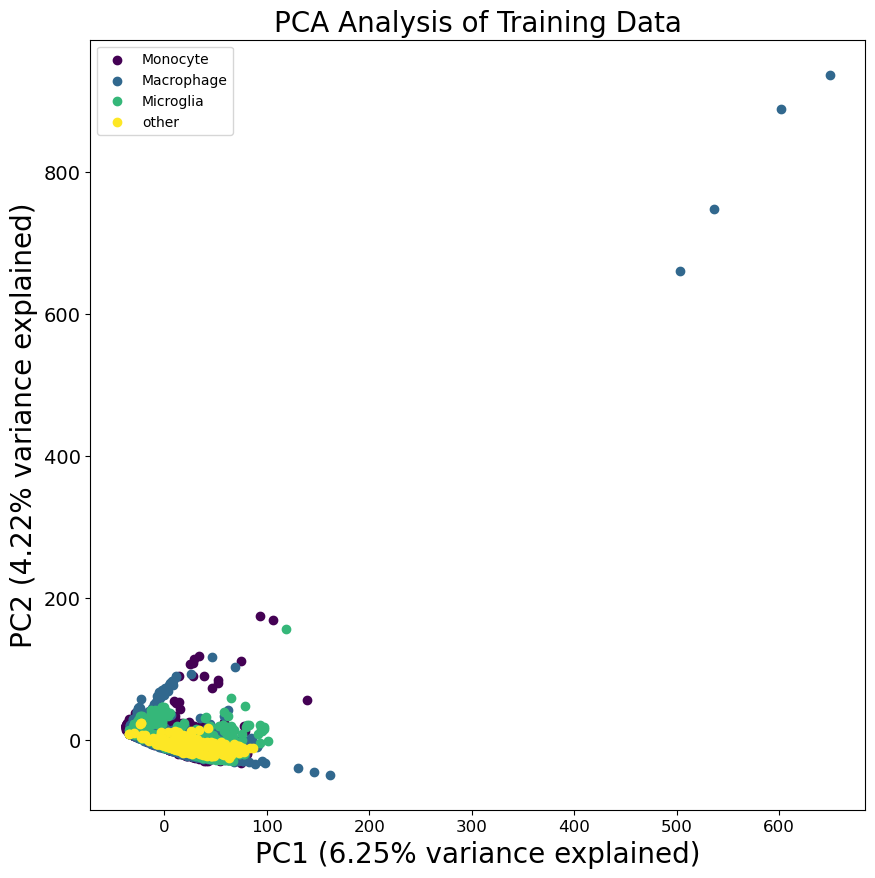

In [8]:
pc1_var = PCA_train.explained_variance_ratio_[0] * 100
pc2_var = PCA_train.explained_variance_ratio_[1] * 100

plt.figure(figsize=(10, 10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel(f'PC1 ({pc1_var:.2f}% variance explained)', fontsize=20)
plt.ylabel(f'PC2 ({pc2_var:.2f}% variance explained)', fontsize=20)
plt.title('PCA Analysis of Training Data', fontsize=20)

label_train_df = pd.DataFrame(data=label_train, columns=['labels'])
unique_labels = label_train_df['labels'].unique()
colors = plt.colormaps['viridis'].resampled(len(unique_labels))

for i, s_type in enumerate(unique_labels):
    indices = label_train_df['labels'] == s_type
    plt.scatter(
        PC_expression_train_df.loc[indices, 'PC1'],
        PC_expression_train_df.loc[indices, 'PC2'],
        color=colors(i),
        label=s_type
    )

plt.legend()
plt.show()

### Below is the training function for a keras NN model

In [9]:
def NN_training(X_train,y_train,X_test,y_test,TFS,name):

    keras.utils.set_random_seed(10)   
    
    num_unique_y = len(set(y_train))

    le = LabelEncoder()
    
    # Fit on training labels (strings) and transform them to integers
    label_train_int = le.fit_transform(y_train)
    
    # Use the same encoder to transform test labels
    label_test_int = le.transform(y_test)
    
    # Best model in magnussen paper was 2 layers of 250 nodes
    model = keras.Sequential([
        keras.layers.Input(shape=(len(TFs),)),  # there are 13146 TFs
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(num_unique_y, activation='softmax')  # For multiclass classification
    ])

    callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience = 3)
    
    adam = optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999,
        weight_decay=0.01  # replaces old `decay`
    )
    model.compile(loss='sparse_categorical_crossentropy',optimizer=adam,metrics=['accuracy'], )
    history = model.fit(X_train, label_train_int, batch_size=50, epochs=100, verbose=1, validation_split = 0.1, callbacks = [callback])

    model.save("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/" + name + "_trained_NN.keras")

    np.save("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/" + name + "_class_names.npy", le.classes_)

    loss, accuracy = model.evaluate(X_test, label_test_int, verbose=1)

    ### Plot the training epochs ###
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].plot(history.history['loss'], label='Training Loss')
    axes[0].plot(history.history['val_loss'], label='Validation Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{name}: Training and Validation Loss')
    axes[0].legend()
    
    axes[1].plot(history.history['accuracy'], label='Training Accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{name}: Training and Validation Accuracy')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    ######

    # Predictions on test set
    y_prob = model.predict(X_test)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate F1 Metrics
    f1_macro = f1_score(label_test_int, y_pred, average='macro')
    f1_weighted = f1_score(label_test_int, y_pred, average='weighted')
    f1_micro = f1_score(label_test_int,y_pred,average = 'micro')

     # binarize the classes
    cell_classes = np.unique(np.concatenate((label_train_int, label_test_int)))
    y_test_bin = label_binarize(label_test_int, classes=cell_classes)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    roc_auc_labeled = dict()

    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        # Inverse transform the label encoder to get the class label once again
        class_label = le.inverse_transform([cur_class])[0]
        roc_auc_labeled[class_label] = roc_auc[cur_class]
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")

    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_prob.ravel())
    roc_auc_labeled["micro"] = auc(fpr["micro"],tpr["micro"])   

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc_labeled["micro"],
    "roc_auc_per_class": roc_auc_labeled,
    "loss" : loss,
    "accuracy" : accuracy
    }

### Below is the model architecture for Pytorch NN

In [10]:
# nn.Module provides base class Pytorch model. Includes methods that do not need to be defined manually.
class NNClassifier(nn.Module):
    # Defines the model's layers
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # nn.Sequential connects layers in order as shown below
        self.network = nn.Sequential(
            nn.Linear(input_dim, 250), # input layer with 13146 Tfs into 250 nodes
            nn.ELU(), # ELU activation function (Exponential Linear Unit)
            nn.Linear(250, 250), # previous layer's 250 nodes transforms to another 250 nodes/values
            nn.ELU(),
            nn.Linear(250, num_classes) # output provides 1 raw score/logit for each class; softmax converts these logits to probabilies during prediction.
        )
    # Defines how data passes through network
    # calling "model(X_batch)" invokes "foward" and produces output logits
    def forward(self, x):
        return self.network(x)

In [11]:
def pytorch_NN_training(X_train, y_train, X_test, y_test, TFS, name):

    # Sets random seeds for reproducibility in repeated runs
    random.seed(10)
    np.random.seed(10)
    torch.manual_seed(10)
    
    # Sets the seed for GPUs manually 
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(10)

    # Has torch access GPU if one is available
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    print(f"Using device: {device}") # Prints the device that was available/chosen

    # Encode labels to integer values
    le = LabelEncoder()
    # Fit on training labels (strings) and transform them to integers
    label_train_int = le.fit_transform(y_train)
    # Use the same encoder to transform test labels
    label_test_int = le.transform(y_test)

    num_unique_y = len(le.classes_) #number of classes in the data
    input_dim = len(TFS) # number of TFs in the data (should be 13146)

    # Convert inputs to float32 tensors
    X_train = torch.as_tensor(
        np.asarray(X_train), dtype=torch.float32 # convert to numpy array then tensor
    )
    X_test = torch.as_tensor(
        np.asarray(X_test), dtype=torch.float32 # 32-bit floating point
    )

    y_train_tensor = torch.as_tensor(
        label_train_int, dtype=torch.long #nn.CrossEntropyloss() expects long or 64-bit integers 
    )

    ### THIS CREATES A RANDOM SPLIT NOT A STRATIFIED SPLIT FOR VALIDATION SET
    # finds the number of samples to be in validation set or "n_val"
    n_samples = len(X_train)
    n_val = max(1, int(0.1 * n_samples)) # ensures at least one sample is selected
    
    generator = torch.Generator().manual_seed(10) # random number generator
    # generates random permutation of ints from 0 to n_samples-1
    permutation = torch.randperm(
        n_samples, generator=generator
    )
    
    val_idx = permutation[:n_val] # takes idx 0 to n_val for validation set
    train_idx = permutation[n_val:] # takes idx n_val to n_samples for training set

    # Tensor is essentially a reduced dimension vector for each sample
    # TensorDataset pairs each expression vector with corresponding label
    train_dataset = TensorDataset(
        X_train[train_idx],
        y_train_tensor[train_idx]
    )
    val_dataset = TensorDataset(
        X_train[val_idx],
        y_train_tensor[val_idx]
    )

    # DataLoader supplies batches to training loop
    train_loader = DataLoader(
        train_dataset,
        batch_size=50, # 50 sample batches at a time
        shuffle=True
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=50,
        shuffle=False
    )


    # Creates the custom model with defined input/output dimensions
    model = NNClassifier(
        input_dim=input_dim,
        num_classes=num_unique_y
    ).to(device)

    # CrossEntropyLoss combines log-softmax and NLL loss
    criterion = nn.CrossEntropyLoss()

    # AdamW approximates Keras Adam with decoupled weight decay
    # Optimizer adjusts model weights to reduce loss
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001, # learning rate: controls step size of weight updates
        betas=(0.9, 0.999), # controls moving averages of gradients/squared gradients
        weight_decay=0.01 # applies regularization
    )

    patience = 3 # if val loss doesn't improve for 3 epochs, stop training
    best_val_loss = float("inf") # any finite val loss is the best
    epochs_without_improvement = 0 # counts consecutive epochs w/o improving
    best_state = None # stores weights from best epoch

    history = {
    "train_loss": [],
    "val_loss": []
    }

    for epoch in range(100): # 100 epochs of training

        # Training
        model.train()
        train_loss_sum = 0.0
        train_count = 0

        for X_batch, y_batch in train_loader:
            # gets one batch of data each iteration and moves them to model's device
            X_batch = X_batch.to(device) # shape: (50, 13146)
            y_batch = y_batch.to(device) # shape: (50)

            # Step 1 in NN training:
            optimizer.zero_grad() # clears gradients from previous batch
            # Step 2 in NN training:
            logits = model(X_batch) # calls the forward pass for model and gets logits
            loss = criterion(logits, y_batch) # compares logits with correct y labels
            # Step 3 in NN Training:
            loss.backward() # backpropagation of weights; estimates how changing weights change the loss.
            # Step 4 in NN Training: this gets repeated for each batch in each epoch
            optimizer.step() # optimizer updates the weights 
            # Calculates the training data set loss
            batch_size = len(y_batch)
            train_loss_sum += loss.item() * batch_size
            train_count += batch_size

        train_loss = train_loss_sum / train_count # sample-weighted average loss for epoch

        # Validation
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad(): # no_grad() since validation does not updates weights
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                # Call forward pass of the model
                logits = model(X_batch)
                loss = criterion(logits, y_batch)
                # calculates the validation set loss 
                batch_size = len(y_batch)
                val_loss_sum += loss.item() * batch_size
                val_count += batch_size

        val_loss = val_loss_sum / val_count

        print(
            f"Epoch {epoch + 1}/100 - "
            f"Train Loss: {train_loss:.4f} - "
            f"Val Loss: {val_loss:.4f}"
        )

        # Save the best model and check early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = { # copies current best model's parameters to "best_state"
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience: # trigger early stopping w/ previous patience
            print("Early stopping triggered.")
            break

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

    # Restore weights from the best validation epoch
    model.load_state_dict(best_state)
    model.eval()

    # Save model and class names
    save_dir = ("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN")
    os.makedirs(save_dir, exist_ok=True)

    torch.save(model.state_dict(),os.path.join(save_dir, name + "_trained_pytorch.pt"))

    np.save(os.path.join(save_dir, name + "_class_names_pytorch.npy"),le.classes_)

    ### Plot the Training epochs ###
    plt.figure(figsize=(14, 5))

    # Loss
    plt.plot(history["train_loss"], label="Training Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{name}: Training and Validation Loss")
    plt.legend()
    
    plt.tight_layout()
    plt.show()

    # Test-set evaluation
    X_test_device = X_test.to(device)
    y_test_tensor = torch.as_tensor(
        label_test_int, dtype=torch.long
    )

    test_dataset = TensorDataset(
        X_test_device,
        y_test_tensor
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=50,
        shuffle=False
    )

    test_loss_sum = 0.0
    all_probs = []
    all_preds = []

    with torch.no_grad(): # no_grad() since testing does not updates weights
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            probs = torch.softmax(logits, dim=1) # converts logits to probabilities that sum to 1
            preds = torch.argmax(logits, dim=1) # finds the highest probability for each testing sample

            test_loss_sum += loss.item() * len(y_batch)
            all_probs.append(probs.cpu().numpy())
            all_preds.append(preds.cpu().numpy())

    loss = test_loss_sum / len(test_dataset)
    y_prob = np.concatenate(all_probs, axis=0)
    y_pred = np.concatenate(all_preds, axis=0)

    accuracy = np.mean(y_pred == label_test_int)

    # F1 metrics
    f1_macro = f1_score(label_test_int, y_pred, average="macro")
    f1_weighted = f1_score(label_test_int, y_pred, average="weighted")
    f1_micro = f1_score(label_test_int, y_pred, average="micro")

    # One-vs-rest ROC-AUC
    cell_classes = np.arange(num_unique_y)

    y_test_bin = label_binarize(label_test_int, classes=cell_classes)

    # sklearn returns only one column for binary classification
    if num_unique_y == 2:
        y_test_bin = np.column_stack([1 - y_test_bin[:, 0], y_test_bin[:, 0]])

    roc_auc_labeled = {}
    fpr = {}
    tpr = {}

    for i, class_label in enumerate(le.classes_):

        # AUC is undefined if the test set has only one
        # outcome for this one-vs-rest classification
        if len(np.unique(y_test_bin[:, i])) < 2:
            roc_auc_labeled[class_label] = float("nan")
            print(f"AUC for {class_label}: undefined")
            continue
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc_labeled[class_label] = auc(fpr[i], tpr[i])

        print(
            f"AUC for {class_label}: "
            f"{roc_auc_labeled[class_label]:.2f}"
        )
    # Micro-average AUC
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
    roc_auc_labeled["micro"] = auc(fpr["micro"], tpr["micro"])

    return {
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "f1_micro": f1_micro,
        "roc_auc_micro": roc_auc_labeled["micro"],
        "roc_auc_per_class": roc_auc_labeled,
        "loss": loss,
        "accuracy": accuracy
    }


I0000 00:00:1792468501.211709  393908 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43516 MB memory:  -> device: 0, name: NVIDIA L40S, pci bus id: 0000:47:00.0, compute capability: 8.9


Epoch 1/100


2026-10-19 23:55:06.108755: I external/local_xla/xla/service/service.cc:163] XLA service 0x14981401bbb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-19 23:55:06.108778: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA L40S, Compute Capability 8.9
2026-10-19 23:55:06.300071: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-19 23:55:06.723267: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-10-19 23:55:06.968208: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-19 23:55:06.968273: I external/loca

 72/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7373 - loss: 6.6916    

I0000 00:00:1792468519.076879  396481 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


...

146/146 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.8721 - loss: 1.7612 - val_accuracy: 0.9209 - val_loss: 0.5392
Epoch 2/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9637 - loss: 0.1926 - val_accuracy: 0.9679 - val_loss: 0.4243
Epoch 3/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9704 - loss: 0.1238 - val_accuracy: 0.9679 - val_loss: 0.8224
Epoch 4/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9784 - loss: 0.0958 - val_accuracy: 0.9567 - val_loss: 0.5502
Epoch 5/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9851 - loss: 0.0580 - val_accuracy: 0.9518 - val_loss: 0.4851


2026-10-19 23:55:32.956347: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-19 23:55:34.792817: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_37', 8 bytes spill stores, 8 bytes spill loads

2026-10-19 23:55:35.607220: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_37', 68 bytes spill stores, 68 bytes spill loads



58/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9619 - loss: 0.2302 

2026-10-19 23:55:37.693828: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_28', 4 bytes spill stores, 4 bytes spill loads

2026-10-19 23:55:38.055663: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_46', 8 bytes spill stores, 8 bytes spill loads



85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9618 - loss: 0.2751


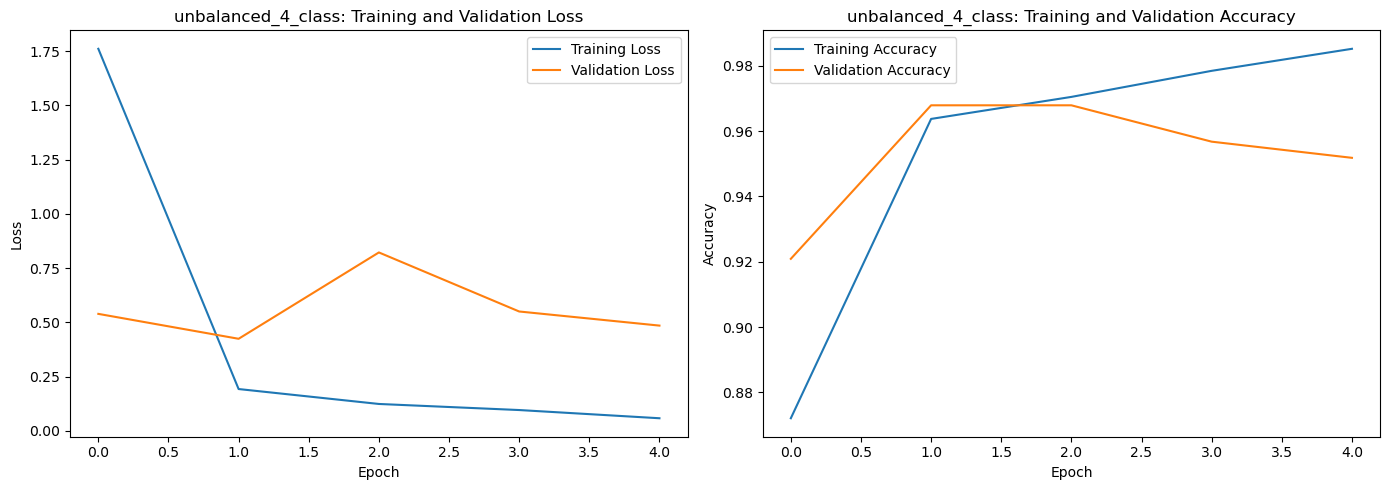

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step   
AUC for class 0: 0.99
AUC for class 1: 1.00
AUC for class 2: 0.99
AUC for class 3: 0.98


In [12]:
unbal_metrics = NN_training(expression_train,label_train,expression_test,label_test,TFs,"unbalanced_4_class")


Using device: cuda
Epoch 1/100 - Train Loss: 0.5043 - Val Loss: 0.1416
Epoch 2/100 - Train Loss: 0.1367 - Val Loss: 0.1303
Epoch 3/100 - Train Loss: 0.0716 - Val Loss: 0.1168
Epoch 4/100 - Train Loss: 0.0363 - Val Loss: 0.1408
Epoch 5/100 - Train Loss: 0.0784 - Val Loss: 0.1980
Epoch 6/100 - Train Loss: 0.0452 - Val Loss: 0.1930
Early stopping triggered.


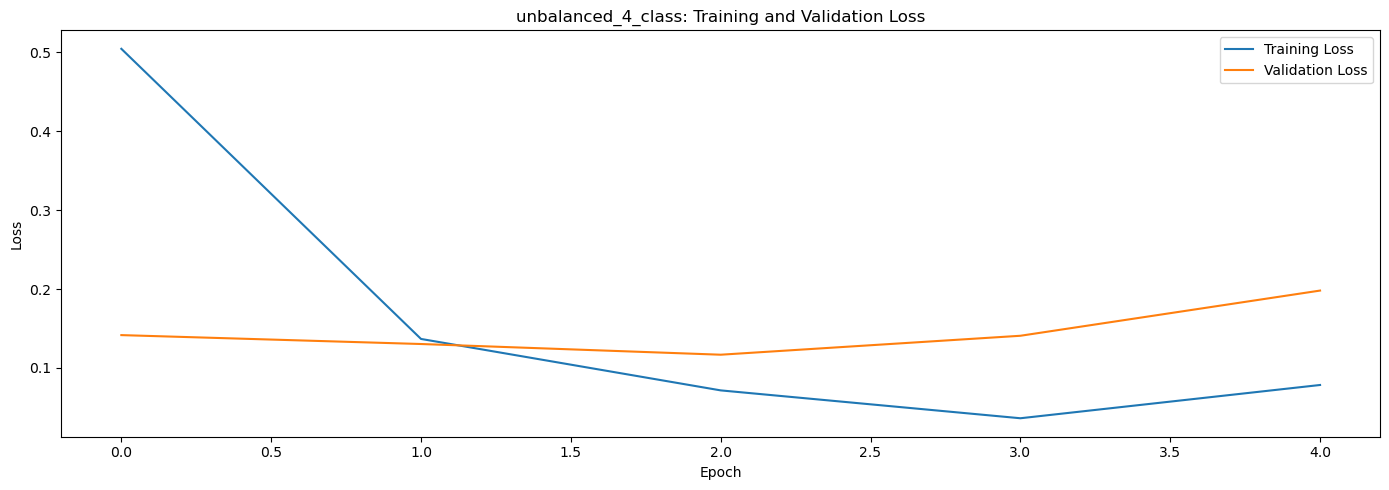

AUC for Macrophage: 0.99
AUC for Microglia: 0.98
AUC for Monocyte: 0.99
AUC for other: 0.99


In [13]:
unbal_metrics_pytorch = pytorch_NN_training(expression_train,label_train,expression_test,label_test,TFs,"unbalanced_4_class")

In [14]:
unbal_metrics

{'f1_macro': 0.942802651528891,
 'f1_weighted': 0.9616010038114003,
 'f1_micro': 0.9617668893838159,
 'roc_auc_micro': 0.9942925630329214,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9943482684846573,
  np.str_('Microglia'): 0.9990291445160804,
  np.str_('Monocyte'): 0.9942511909487891,
  np.str_('other'): 0.9783325070718264,
  'micro': 0.9942925630329214},
 'loss': 0.2751189172267914,
 'accuracy': 0.9617668986320496}

In [15]:
unbal_metrics_pytorch

{'f1_macro': 0.9582845361725636,
 'f1_weighted': 0.9745418980654249,
 'f1_micro': 0.9747587230883444,
 'roc_auc_micro': 0.9950643478583568,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9940573428131207,
  np.str_('Microglia'): 0.9820886588998228,
  np.str_('Monocyte'): 0.9933373031626308,
  np.str_('other'): 0.9939816569945467,
  'micro': 0.9950643478583568},
 'loss': 0.18657343176421007,
 'accuracy': np.float64(0.9747587230883444)}

Epoch 1/100
290/297 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8507 - loss: 2.1947   

2026-10-19 23:56:05.827561: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-19 23:56:05.827630: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-19 23:56:05.827664: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-19 23:56:05.827676: I external/l

297/297 ━━━━━━━━━━━━━━━━━━━━ 17s 52ms/step - accuracy: 0.9232 - loss: 0.7817 - val_accuracy: 0.9958 - val_loss: 0.0220
Epoch 2/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9796 - loss: 0.0866 - val_accuracy: 0.9945 - val_loss: 0.0203
Epoch 3/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9742 - loss: 0.1884 - val_accuracy: 1.0000 - val_loss: 0.0064
Epoch 4/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9773 - loss: 0.1185 - val_accuracy: 1.0000 - val_loss: 0.0031
Epoch 5/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9885 - loss: 0.0631 - val_accuracy: 0.9776 - val_loss: 0.1088
Epoch 6/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9871 - loss: 0.0707 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 7/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9941 - loss: 0.0323 - val_accuracy: 1.0000 - val_loss: 0.0032
Epoch 8/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9974 - loss: 0.0114 - val_accuracy: 1.00

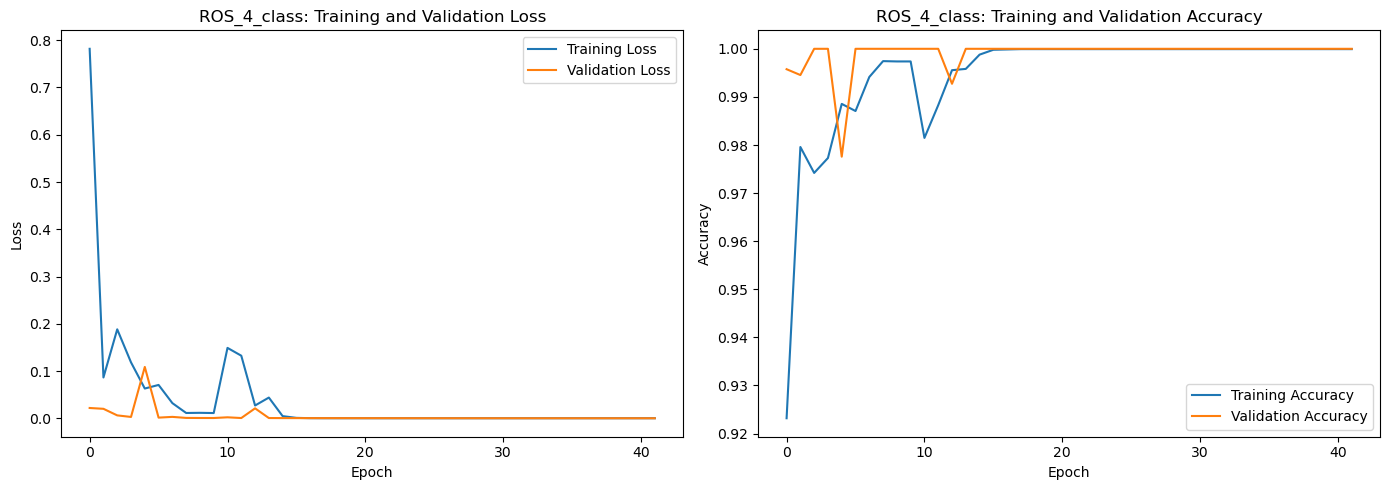

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step   
AUC for class 0: 1.00
AUC for class 1: 1.00
AUC for class 2: 1.00
AUC for class 3: 0.98


In [16]:
ROS_metrics = NN_training(expression_ros,label_ros,expression_test,label_test,TFs,"ROS_4_class")


Using device: cuda
Epoch 1/100 - Train Loss: 0.2495 - Val Loss: 0.1319
Epoch 2/100 - Train Loss: 0.0845 - Val Loss: 0.0476
Epoch 3/100 - Train Loss: 0.0296 - Val Loss: 0.0420
Epoch 4/100 - Train Loss: 0.0197 - Val Loss: 0.0276
Epoch 5/100 - Train Loss: 0.0111 - Val Loss: 0.0344
Epoch 6/100 - Train Loss: 0.0404 - Val Loss: 0.0691
Epoch 7/100 - Train Loss: 0.0790 - Val Loss: 0.0525
Early stopping triggered.


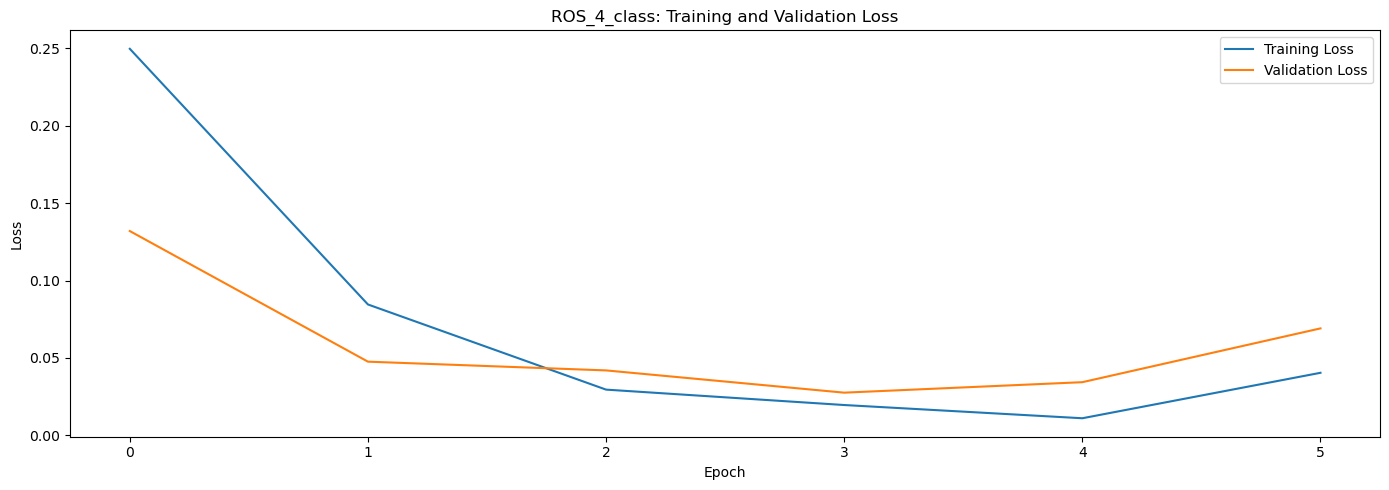

AUC for Macrophage: 0.99
AUC for Microglia: 1.00
AUC for Monocyte: 1.00
AUC for other: 1.00


In [17]:
ROS_metrics_pytorch = pytorch_NN_training(expression_ros,label_ros,expression_test,label_test,TFs,"ROS_4_class")


In [18]:
ROS_metrics

{'f1_macro': 0.9814109452515033,
 'f1_weighted': 0.9866350707742714,
 'f1_micro': 0.9866369710467706,
 'roc_auc_micro': 0.9972260021490928,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9965062814420167,
  np.str_('Microglia'): 0.9992341552614712,
  np.str_('Monocyte'): 0.9964585814476644,
  np.str_('other'): 0.9766411011635706,
  'micro': 0.9972260021490928},
 'loss': 0.29934385418891907,
 'accuracy': 0.9866369962692261}

In [19]:
ROS_metrics_pytorch

{'f1_macro': 0.9788116595033418,
 'f1_weighted': 0.9792305233450035,
 'f1_micro': 0.9792130660727543,
 'roc_auc_micro': 0.9971814284063479,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9941800362917448,
  np.str_('Microglia'): 0.9962108358782943,
  np.str_('Monocyte'): 0.9955121631158749,
  np.str_('other'): 0.9995042430958561,
  'micro': 0.9971814284063479},
 'loss': 0.14615517060577304,
 'accuracy': np.float64(0.9792130660727543)}

Epoch 1/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9241 - loss: 0.7916 - val_accuracy: 1.0000 - val_loss: 0.0060
Epoch 2/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9783 - loss: 0.1224 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 3/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9811 - loss: 0.0882 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 4/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9830 - loss: 0.1038 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 5/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9864 - loss: 0.0655 - val_accuracy: 1.0000 - val_loss: 6.3507e-04
Epoch 6/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9908 - loss: 0.0581 - val_accuracy: 0.9994 - val_loss: 0.0016
Epoch 7/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9813 - loss: 0.2001 - val_accuracy: 1.0000 - val_loss: 4.4527e-04
Epoch 8/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9916 - loss: 0.0523 -

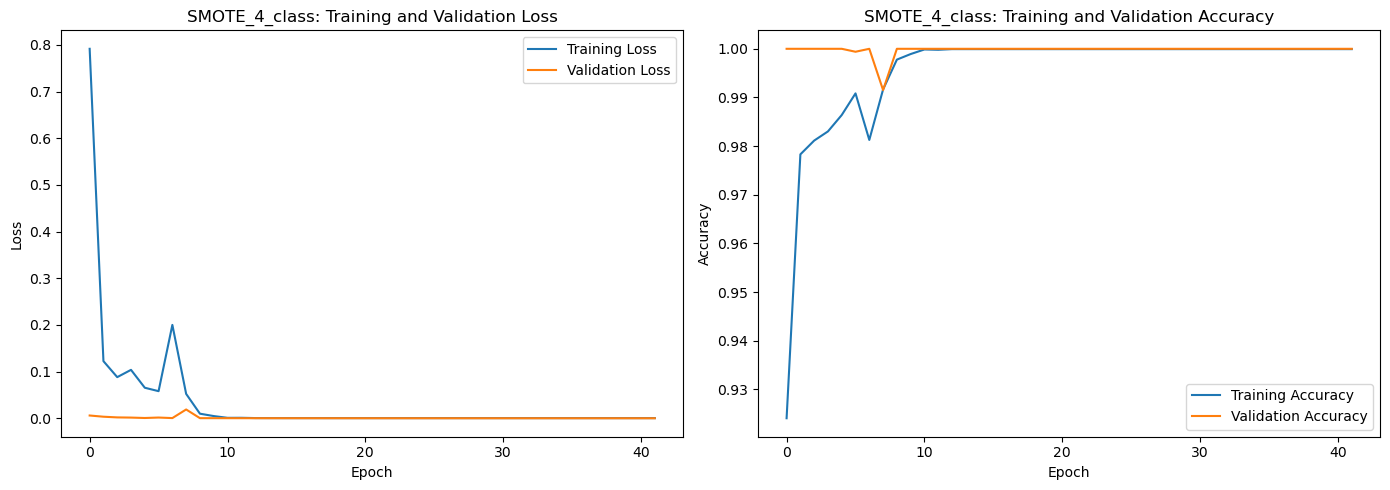

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step   
AUC for class 0: 0.99
AUC for class 1: 1.00
AUC for class 2: 0.99
AUC for class 3: 0.99


In [20]:
SMOTE_metrics = NN_training(expression_SMOTE,label_SMOTE,expression_test,label_test,TFs,"SMOTE_4_class")

Using device: cuda
Epoch 1/100 - Train Loss: 0.2843 - Val Loss: 0.0570
Epoch 2/100 - Train Loss: 0.0518 - Val Loss: 0.0506
Epoch 3/100 - Train Loss: 0.0398 - Val Loss: 0.0374
Epoch 4/100 - Train Loss: 0.0186 - Val Loss: 0.0576
Epoch 5/100 - Train Loss: 0.0340 - Val Loss: 0.0660
Epoch 6/100 - Train Loss: 0.0349 - Val Loss: 0.0151
Epoch 7/100 - Train Loss: 0.0167 - Val Loss: 0.0293
Epoch 8/100 - Train Loss: 0.0269 - Val Loss: 0.0290
Epoch 9/100 - Train Loss: 0.0124 - Val Loss: 0.0343
Early stopping triggered.


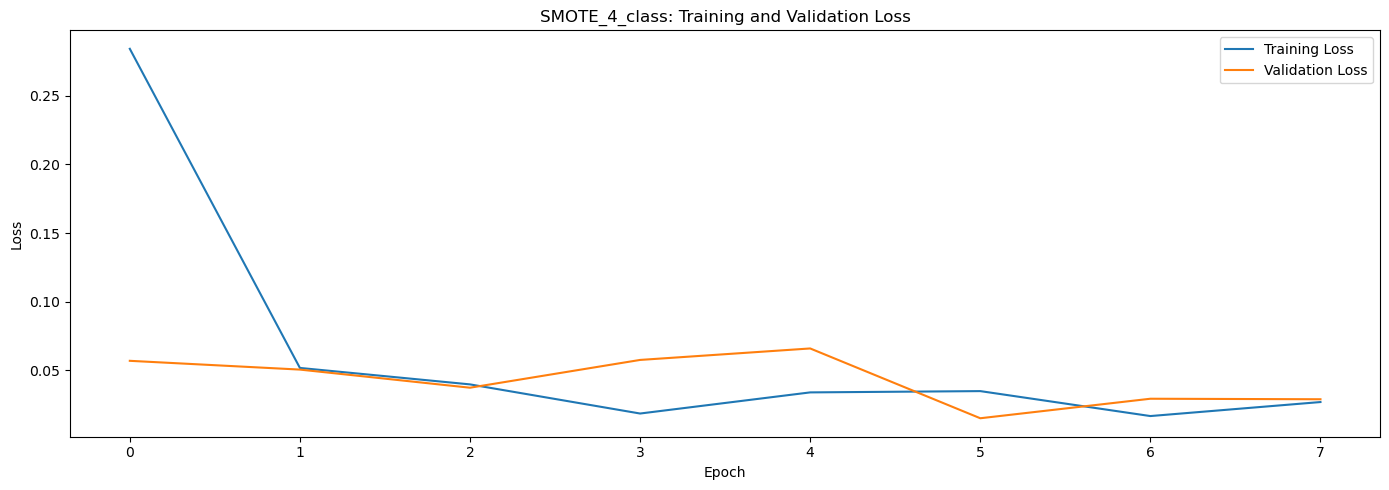

AUC for Macrophage: 1.00
AUC for Microglia: 1.00
AUC for Monocyte: 1.00
AUC for other: 0.99


In [21]:
SMOTE_metrics_pytorch = pytorch_NN_training(expression_SMOTE,label_SMOTE,expression_test,label_test,TFs,"SMOTE_4_class")

In [22]:
SMOTE_metrics

{'f1_macro': 0.9760628604249033,
 'f1_weighted': 0.9843836165536178,
 'f1_micro': 0.9844097995545658,
 'roc_auc_micro': 0.9968914120245216,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9946380339341737,
  np.str_('Microglia'): 0.9989890849451419,
  np.str_('Monocyte'): 0.9947636848837721,
  np.str_('other'): 0.991654151235018,
  'micro': 0.9968914120245216},
 'loss': 0.30759721994400024,
 'accuracy': 0.9844098091125488}

In [23]:
SMOTE_metrics_pytorch

{'f1_macro': 0.9824741821020428,
 'f1_weighted': 0.9847698349100062,
 'f1_micro': 0.9847809948032665,
 'roc_auc_micro': 0.9975195780003296,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9964479802855074,
  np.str_('Microglia'): 0.9999811484372055,
  np.str_('Monocyte'): 0.9960053592695514,
  np.str_('other'): 0.9883059694963693,
  'micro': 0.9975195780003296},
 'loss': 0.1106470349771019,
 'accuracy': np.float64(0.9847809948032665)}

Epoch 1/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9162 - loss: 0.7934 - val_accuracy: 0.9915 - val_loss: 0.1091
Epoch 2/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9725 - loss: 0.1598 - val_accuracy: 1.0000 - val_loss: 0.0061
Epoch 3/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9846 - loss: 0.0906 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 4/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9921 - loss: 0.0419 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 5/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9930 - loss: 0.0353 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 6/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9869 - loss: 0.0607 - val_accuracy: 1.0000 - val_loss: 8.7575e-04
Epoch 7/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9909 - loss: 0.0484 - val_accuracy: 1.0000 - val_loss: 7.0690e-04
Epoch 8/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9910 - loss: 0.0529 -

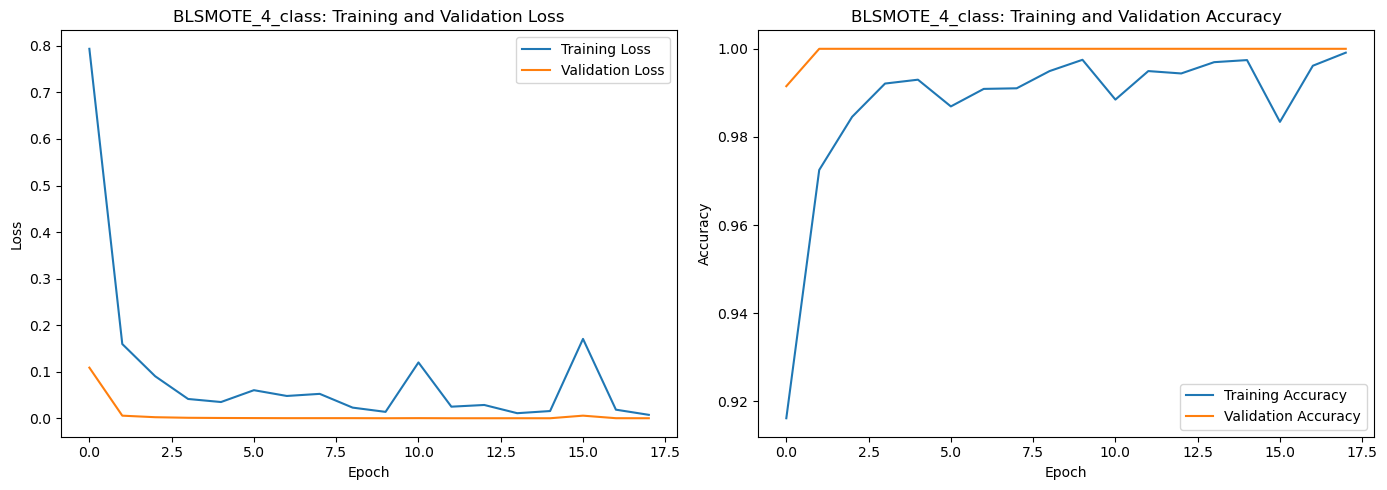

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step    
AUC for class 0: 0.99
AUC for class 1: 1.00
AUC for class 2: 0.99
AUC for class 3: 0.99


In [24]:
BLSMOTE_metrics = NN_training(expression_BLSMOTE,label_BLSMOTE,expression_test,label_test,TFs,"BLSMOTE_4_class")

Using device: cuda
Epoch 1/100 - Train Loss: 0.2881 - Val Loss: 0.2083
Epoch 2/100 - Train Loss: 0.0677 - Val Loss: 0.0417
Epoch 3/100 - Train Loss: 0.0308 - Val Loss: 0.0574
Epoch 4/100 - Train Loss: 0.0591 - Val Loss: 0.0812
Epoch 5/100 - Train Loss: 0.0744 - Val Loss: 0.2257
Early stopping triggered.


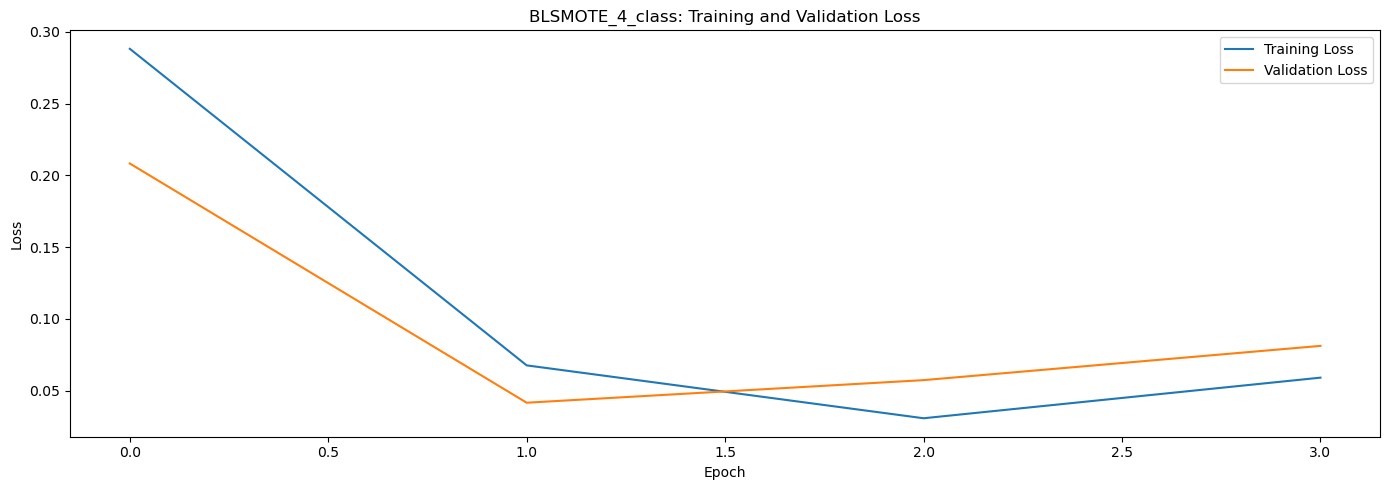

AUC for Macrophage: 0.99
AUC for Microglia: 1.00
AUC for Monocyte: 0.99
AUC for other: 1.00


In [25]:
BLSMOTE_metrics_pytorch = pytorch_NN_training(expression_BLSMOTE,label_BLSMOTE,expression_test,label_test,TFs,"BLSMOTE_4_class")

In [26]:
BLSMOTE_metrics

{'f1_macro': 0.9765266195948448,
 'f1_weighted': 0.9821419857516263,
 'f1_micro': 0.9821826280623608,
 'roc_auc_micro': 0.9958265335985437,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.993978447715755,
  np.str_('Microglia'): 0.9972724145081628,
  np.str_('Monocyte'): 0.9928471395174452,
  np.str_('other'): 0.990952436499373,
  'micro': 0.9958265335985437},
 'loss': 0.47314512729644775,
 'accuracy': 0.9821826219558716}

In [27]:
BLSMOTE_metrics_pytorch

{'f1_macro': 0.976567389205754,
 'f1_weighted': 0.9807070416029362,
 'f1_micro': 0.9806978470675576,
 'roc_auc_micro': 0.9976387628147788,
 'roc_auc_per_class': {np.str_('Macrophage'): 0.9946345532681135,
  np.str_('Microglia'): 0.999985861327904,
  np.str_('Monocyte'): 0.9948987693529178,
  np.str_('other'): 0.998767898282348,
  'micro': 0.9976387628147788},
 'loss': 0.09751636764752307,
 'accuracy': np.float64(0.9806978470675576)}

# Node Light up Test is below

In [28]:
# Import expression data and transcript data from filtered h5 file
filtered_file_tf = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_4_class/filtered_ARCHS4_TFs_4_class.h5", 'r')
ensembl_id = filtered_file_tf['ensembl_id'][...]
symbol = filtered_file_tf['symbol'][...]
expression = filtered_file_tf['data/filtered_expression'][...]
filtered_file_tf.close()

# Read all names and decode bytes to strings
if isinstance(ensembl_id[0], bytes):
    ensembl_id = [s.decode('utf-8') for s in ensembl_id]

# Read all names and decode bytes to strings
if isinstance(symbol[0], bytes):
    symbol = [s.decode('utf-8') for s in symbol]

# Make the transcript ID be the symbol _ ensembl ID
transcript_ID = []
for idx, sym in enumerate(symbol):
    ID = sym + "_" + ensembl_id[idx]
    transcript_ID.append(ID)

In [29]:
expression.shape

(13146, 10775)

In [30]:
len(transcript_ID)

13146

In [31]:
class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/unbalanced_4_class_class_names.npy')
class_names

array(['Macrophage', 'Microglia', 'Monocyte', 'other'], dtype='<U10')

### Implement the Node Light up technique as a function

In [32]:
def node_light_up(model_name,tf_names,express_mat,cell_type,NN_model,TFS): # NN_model = "keras" or "pytorch"

    # Has torch access GPU if one is available
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    print(f"Using device: {device}") # Prints the device that was available/chosen

    # create square matrix of zeros. Number of rows and cols is number of TFs
    inp = np.zeros((len(TFS),len(TFS)))
    # Generate baseline TF expression values for the inp square matrix
    tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)
    for i in range(inp.shape[1]):
        inp[i, :] = tf_data.values
    # Generate doubled and halved expression for TFs. Only diagonals of the baseline square matrix is doubled or halved
    half = inp.copy()
    double = inp.copy()
    half[np.eye(half.shape[0]).astype(bool)] = 0.5*half[np.eye(half.shape[0]).astype(bool)]
    double[np.eye(double.shape[0]).astype(bool)] = 2*double[np.eye(double.shape[0]).astype(bool)]
    
    if (NN_model == "keras"):
        # load train keras model
        model = load_model('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_trained_NN.keras')
        # Import cell class names 
        class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_class_names.npy')
        cell_type_index = np.where(class_names == cell_type)[0][0]

        background_pred = model.predict(inp)
        background_idx = np.argmax(background_pred, axis=1)
        background_labels = class_names[background_idx]
        
        double_pred = model.predict(double)
        double_idx = np.argmax(double_pred, axis=1)
        double_labels = class_names[double_idx]
        
        half_pred = model.predict(half)
        half_idx = np.argmax(half_pred, axis=1)
        half_labels = class_names[half_idx]
    
        double_background = double_pred[:,cell_type_index] - background_pred[:,cell_type_index]
        half_background = half_pred[:,cell_type_index] - background_pred[:,cell_type_index]
    
        score = (double_background - half_background) / 2
        score = pd.DataFrame(score, index=tf_names, columns=[cell_type])
        score_sorted = score.sort_values(by=cell_type, ascending=True)
            
    elif (NN_model == "pytorch"):
        class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_class_names_pytorch.npy')
        # Recreate the architecture
        model = NNClassifier(input_dim=len(TFS),num_classes=len(class_names))
        # Load the trained weights
        model.load_state_dict(
            torch.load(
                '/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + "_trained_pytorch.pt",
                map_location=device,
                weights_only=True
            )
        )
        model = model.to(device)
        model.eval()

        cell_type_index = np.where(class_names == cell_type)[0][0]

        inp_tensor = torch.as_tensor(
            inp,
            dtype=torch.float32,
            device=device
        )
        half_tensor = torch.as_tensor(
            half,
            dtype=torch.float32,
            device=device
        )
        double_tensor = torch.as_tensor(
            double,
            dtype=torch.float32,
            device=device
        )
        
        with torch.no_grad():
            logits_background = model(inp_tensor)
            logits_half = model(half_tensor)
            logits_double = model(double_tensor)
            y_prob_background = torch.softmax(logits_background, dim=1).cpu().numpy()
            y_prob_half = torch.softmax(logits_half, dim=1).cpu().numpy()
            y_prob_double = torch.softmax(logits_double, dim=1).cpu().numpy()

        double_background = y_prob_double[:,cell_type_index] - y_prob_background[:,cell_type_index]
        half_background = y_prob_half[:,cell_type_index] - y_prob_background[:,cell_type_index]
    
        score = (double_background - half_background) / 2
        score = pd.DataFrame(score, index=tf_names, columns=[cell_type])
        score_sorted = score.sort_values(by=cell_type, ascending=True)

            
    else:
        raise ValueError("Please enter 'keras' or 'pytorch' for NN_model.")

    return score_sorted



### Keras Models Node Light Up Followed by Pytorch Models Node Light Up

In [33]:
unbalanced_macrophages = node_light_up("unbalanced_4_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


362/411 ━━━━━━━━━━━━━━━━━━━━ 0s 978us/step  

2026-10-19 23:58:39.160832: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-19 23:58:39.444820: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9', 4 bytes spill stores, 4 bytes spill loads

2026-10-19 23:58:41.220041: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18', 8 bytes spill stores, 8 bytes spill loads

2026-10-19 23:58:41.521413: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_27', 8 bytes spill st

411/411 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [34]:
unbalanced_macrophages.head(n=20)

,Macrophage
JUNB_ENST00000302754,-0.000248
CEBPB_ENST00000303004,-0.000184
SPI1_ENST00000378538,-0.000111
ATF4_ENST00000674920,-0.000099
STAT6_ENST00000300134,-0.000085
KLF6_ENST00000542957,-0.000078
KMT2A_ENST00000648029,-0.000078
FOS_ENST00000556324,-0.000075
SON_ENST00000492229,-0.000068
KLF6_ENST00000497571,-0.000062


In [35]:
for idx, t in enumerate(unbalanced_macrophages.index):
    if "ZNF385A" in str(t):
        print(idx)

184
307
366
828
834
2106
3235
4262
11198
11721
12001
12267
12925
13021
13081


In [36]:
unbalanced_microglia = node_light_up("unbalanced_4_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [37]:
unbalanced_microglia.head(n=20)

,Microglia
JUNB_ENST00000302754,-1.355108e-06
FOS_ENST00000303562,-4.745160e-07
YBX1_ENST00000436427,-4.353908e-07
CEBPB_ENST00000303004,-2.606668e-07
STAT6_ENST00000300134,-2.156918e-07
KLF6_ENST00000497571,-2.090390e-07
KLF6_ENST00000542957,-1.894109e-07
ATF4_ENST00000674920,-1.665256e-07
KMT2A_ENST00000648029,-1.241993e-07
TRAFD1_ENST00000412615,-1.226017e-07


In [38]:
unbalanced_monocyte = node_light_up("unbalanced_4_class",transcript_ID,expression,"Monocyte","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [39]:
unbalanced_monocyte.head(n=20)

,Monocyte
YBX1_ENST00000467957,-0.000192
JUN_ENST00000678696,-0.000090
NME2_ENST00000512737,-0.000086
YBX1_ENST00000436427,-0.000086
EGR1_ENST00000239938,-0.000085
SPI1_ENST00000227163,-0.000082
CEBPD_ENST00000408965,-0.000079
ZNF706_ENST00000517844,-0.000078
MSC_ENST00000325509,-0.000059
USF2_ENST00000599625,-0.000055


In [40]:
for idx, t in enumerate(unbalanced_monocyte.index):
    if "ZNF385A" in str(t):
        print(idx)

65
167
222
893
1185
1666
1924
8508
10145
10829
12319
12349
12782
12864
12964


In [41]:
unbalanced_other = node_light_up("unbalanced_4_class",transcript_ID,expression,"other","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [42]:
unbalanced_other.head(n=20)

,other
JUNB_ENST00000302754,-0.000012
SPI1_ENST00000378538,-0.000005
YBX1_ENST00000332220,-0.000003
KLF6_ENST00000497571,-0.000003
KLF6_ENST00000542957,-0.000002
NFKB1_ENST00000652569,-0.000002
CSRNP1_ENST00000273153,-0.000002
NFKB2_ENST00000651907,-0.000002
STAT6_ENST00000300134,-0.000002
EGR2_ENST00000242480,-0.000002


In [43]:
for idx, t in enumerate(unbalanced_other.index):
    if "ZNF385A" in str(t):
        print(idx)

10
70
205
315
328
353
729
863
1069
3459
10060
11172
11615
12562
12886


In [44]:
ROS_macrophages = node_light_up("ROS_4_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [45]:
ROS_macrophages.head(n=20) 

,Macrophage
FOS_ENST00000303562,-3.545894e-10
KLF6_ENST00000542957,-3.334141e-10
KMT2A_ENST00000648029,-3.182822e-10
SPI1_ENST00000378538,-2.727383e-10
YBX1_ENST00000332220,-2.533912e-10
ATF4_ENST00000674920,-2.448179e-10
STAT6_ENST00000300134,-2.230212e-10
NFKB1_ENST00000652569,-2.072242e-10
MAFB_ENST00000373313,-1.844787e-10
ZNF385A_ENST00000394313,-1.778028e-10


In [46]:
ROS_microglia = node_light_up("ROS_4_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [47]:
ROS_microglia.head(n=20) # doubling

,Microglia
FOS_ENST00000303562,-1.640158e-17
MAFB_ENST00000373313,-1.496770e-17
KMT2A_ENST00000648029,-1.480547e-17
JUNB_ENST00000302754,-1.367066e-17
YBX1_ENST00000332220,-1.339224e-17
KLF6_ENST00000542957,-1.241001e-17
NFKB1_ENST00000652569,-1.078678e-17
STAT6_ENST00000300134,-1.067161e-17
SPI1_ENST00000378538,-1.035265e-17
ZNF385A_ENST00000394313,-1.015625e-17


In [48]:
SMOTE_macrophages = node_light_up("SMOTE_4_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [49]:
SMOTE_macrophages.head(n=20) 

,Macrophage
JUNB_ENST00000302754,-0.400649
FOS_ENST00000303562,-0.362485
KLF6_ENST00000542957,-0.324874
YBX1_ENST00000332220,-0.270188
SPI1_ENST00000378538,-0.238615
CEBPB_ENST00000303004,-0.184811
STAT6_ENST00000300134,-0.179340
ATF4_ENST00000674920,-0.153204
KMT2A_ENST00000648029,-0.136388
FOS_ENST00000554617,-0.116583


In [50]:
SMOTE_microglia = node_light_up("SMOTE_4_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [51]:
SMOTE_microglia.head(n=20)

,Microglia
CEBPD_ENST00000408965,-9.389216e-15
YBX1_ENST00000436427,-8.213301e-15
MSC_ENST00000325509,-7.011177e-15
MAFB_ENST00000373313,-6.989975e-15
YBX1_ENST00000467957,-5.727641e-15
FOS_ENST00000555686,-5.239436e-15
JUNB_ENST00000302754,-5.054959e-15
ZNF385A_ENST00000394313,-4.641605e-15
PLSCR1_ENST00000342435,-3.815993e-15
ZNF706_ENST00000517844,-3.270542e-15


In [52]:
BLSMOTE_macrophages = node_light_up("BLSMOTE_4_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [53]:
BLSMOTE_macrophages.head(n=20)

,Macrophage
FOS_ENST00000303562,-0.000008
JUNB_ENST00000302754,-0.000006
CEBPB_ENST00000303004,-0.000004
SPI1_ENST00000378538,-0.000004
STAT6_ENST00000300134,-0.000003
YBX1_ENST00000436427,-0.000003
KMT2A_ENST00000648029,-0.000003
ATF4_ENST00000674920,-0.000002
KLF6_ENST00000542957,-0.000001
FOSL2_ENST00000264716,-0.000001


In [54]:
BLSMOTE_microglia = node_light_up("BLSMOTE_4_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-20385066/ipykernel_393908/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [55]:
BLSMOTE_microglia.head(n=20)

,Microglia
YBX1_ENST00000436427,-2.968052e-13
JUNB_ENST00000302754,-1.833552e-13
FOS_ENST00000303562,-1.810863e-13
CEBPB_ENST00000303004,-1.445120e-13
STAT6_ENST00000300134,-9.834627e-14
SPI1_ENST00000378538,-9.809545e-14
KMT2A_ENST00000648029,-9.241126e-14
MAFB_ENST00000373313,-8.508573e-14
CEBPD_ENST00000408965,-7.389755e-14
NFKB1_ENST00000652569,-7.009538e-14
